# Notebook 01 — Audit, Contrôle et Préparation des Données (2000–2025)

## Objectif
Répondre à la question préalable fondamentale : **Nos données sont-elles suffisamment propres, cohérentes et qualifiées pour réaliser une analyse économétrique solide ?**

## Étapes de ce Notebook
1. Importation des bibliothèques et configuration de l'environnement.
2. Chargement du jeu de données brut $N = 26$ observations (2000–2025).
3. Contrôle de la structure, des types de variables, des valeurs manquantes et des doublons.
4. Contrôles arithmétiques des ratios ($PIB/hab$, $NTL/hab$) et des taux de croissance.
5. Audit des capteurs satellitaires (DMSP/OLS vs VIIRS/DNB).
6. Détection et analyse des anomalies majeures (**2012** et **2017**).
7. Création des variables de contrôle d'anomalies et exportation du dataset audité.

In [9]:
# ==============================================================================
# 1. IMPORTATION DES BIBLIOTHÈQUES & CONFIGURATION
# ==============================================================================
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Configuration de l'affichage Pandas et des graphiques
pd.set_option('display.max_columns', None)
pd.set_option('display.float_format', lambda x: '%.6f' % x)
sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (10, 5)

print("[✓] Bibliothèques importées avec succès.")

# ==============================================================================
# 2. CHARGEMENT AUTOMATIQUE DE LA BASE DE DONNÉES DEPUIS LE FICHIER CSV
# ==============================================================================
# Détection dynamique de la racine du projet
project_root = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()

# Recherche du fichier CSV dans data/final/ ou data/raw/
data_paths = [
    project_root / "data" / "final" / "niger_ntl_gdp_2000_2025.csv",
    project_root / "data" / "raw" / "niger_ntl_gdp_2000_2025.csv",
    project_root / "niger_ntl_gdp_2000_2025.csv"
]

csv_path = None
for p in data_paths:
    if p.exists():
        csv_path = p
        break

if csv_path is None:
    raise FileNotFoundError(
        "Le fichier niger_ntl_gdp_2000_2025.csv est introuvable dans data/final/ ni dans data/raw/.\n"
        "Assurez-vous d'exécuter le script 04_build_dataset.py au préalable."
    )

df_raw = pd.read_csv(csv_path)
print(f"[✓] Fichier CSV chargé avec succès depuis : {csv_path}")
print(f"[✓] Dimension du dataset : {df_raw.shape[0]} lignes et {df_raw.shape[1]} colonnes.")
df_raw.head(3)

[✓] Bibliothèques importées avec succès.
[✓] Fichier CSV chargé avec succès depuis : c:\Niger & Big Data\NTL et PIB Niger\niger_ntl_gdp\data\final\niger_ntl_gdp_2000_2025.csv
[✓] Dimension du dataset : 26 lignes et 14 colonnes.


,year,gdp_real,gdp_growth,population,gdp_pc_real,ntl_sum_adj,ntl_mean_adj,ntl_per_capita,ntl_growth,ntl_lit_count,sensor,dummy_viirs,ntl_sum,ntl_mean
0,2000,2673528889000,-1.208478,11509630,392.898617,43295.894835,0.034703,0.003762,NaN,979.760784,DMSP/OLS,0,20526.486275,0.016452
1,2001,2867844575300,7.268135,11920647,406.923494,42202.590058,0.033826,0.003540,-2.525193,949.196078,DMSP/OLS,0,20008.152941,0.016037
2,2002,3008898666900,4.918471,12349144,412.123793,41379.888037,0.033167,0.003351,-1.949411,921.454902,DMSP/OLS,0,19618.111765,0.015724


## Section 3 : Audit de la Structure des Données

Nous vérifions :
1. Les types de données de chaque colonne.
2. La présence de valeurs manquantes (`NaN`) ou de doublons sur la variable `year`.
3. La continuité temporelle exacte de 2000 à 2025 sans rupture ni omission d'année.

In [10]:
# ==============================================================================
# 3. AUDIT DES TYPES, VALEURS MANQUANTES ET DOUBLONS
# ==============================================================================
print("--- 3.1 Infos Générales et Types ---")
print(df_raw.info())

print("\n--- 3.2 Vérification des Valeurs Manquantes ---")
missing_summary = df_raw.isnull().sum()
print(missing_summary[missing_summary > 0] if missing_summary.sum() > 0 else "[✓] Aucune valeur manquante détectée.")

print("\n--- 3.3 Vérification des Doublons sur l'Année ---")
duplicates = df_raw.duplicated(subset=['year']).sum()
print(f"[✓] Doublons d'années : {duplicates}")

# Vérification de la continuité temporelle 2000-2025
expected_years = set(range(2000, 2026))
actual_years = set(df_raw['year'].astype(int))
missing_years = expected_years - actual_years

if not missing_years:
    print(f"[✓] Continuité temporelle parfaite : 26 années consécutives ({min(actual_years)} à {max(actual_years)}).")
else:
    print(f"[⚠] Années manquantes détectées : {missing_years}")

--- 3.1 Infos Générales et Types ---
<class 'pandas.DataFrame'>
RangeIndex: 26 entries, 0 to 25
Data columns (total 14 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   year            26 non-null     int64  
 1   gdp_real        26 non-null     int64  
 2   gdp_growth      26 non-null     float64
 3   population      26 non-null     int64  
 4   gdp_pc_real     26 non-null     float64
 5   ntl_sum_adj     26 non-null     float64
 6   ntl_mean_adj    26 non-null     float64
 7   ntl_per_capita  26 non-null     float64
 8   ntl_growth      25 non-null     float64
 9   ntl_lit_count   26 non-null     float64
 10  sensor          26 non-null     str    
 11  dummy_viirs     26 non-null     int64  
 12  ntl_sum         26 non-null     float64
 13  ntl_mean        26 non-null     float64
dtypes: float64(9), int64(4), str(1)
memory usage: 3.0 KB
None

--- 3.2 Vérification des Valeurs Manquantes ---
ntl_growth    1
dtype: int64

--- 3.3 V

## Section 4 : Contrôles Arithmétiques

Nous recalculons et comparons les variables théoriques avec celles présentes dans le dataset :
* **PIB réel par habitant** : $GDP_{pc, t} = \frac{GDP_{\text{real}, t}}{\text{Population}_t}$
* **NTL par habitant** : $NTL_{pc, t} = \frac{NTL_{\text{sum\_adj}, t}}{\text{Population}_t}$
* **Taux de croissance du NTL** : $g_{NTL, t} = 100 \times \left(\frac{NTL_{\text{sum\_adj}, t}}{NTL_{\text{sum\_adj}, t-1}} - 1\right)$
* **Cohérence du capteur** : Correspondance stricte entre `sensor` (`DMSP/OLS` vs `VIIRS`) et `dummy_viirs` ($0$ vs $1$).

In [11]:
# ==============================================================================
# 4. CONTRÔLES ARITHMÉTIQUES ET HARMONISATION MONÉTAIRE (BLOC 2 CORRIGÉ)
# ==============================================================================
df_audit = df_raw.copy()

# 4.1 Création du PIB réel par habitant en Monnaie Locale (FCFA)
# gdp_real (FCFA) / population
df_audit['gdp_pc_local'] = df_audit['gdp_real'] / df_audit['population']

print(f"[✓] Variable 'gdp_pc_local' créée (FCFA par habitant).")
print(f"    - Exemple 2000 : {df_audit.loc[df_audit['year']==2000, 'gdp_pc_local'].values[0]:.2f} FCFA/hab")
print(f"    - Exemple 2025 : {df_audit.loc[df_audit['year']==2025, 'gdp_pc_local'].values[0]:.2f} FCFA/hab")

# 4.2 Explication du ratio USD vs FCFA (gdp_pc_real WDI vs gdp_pc_local)
# Taux de conversion implicite WDI ($ / FCFA)
df_audit['implicit_fx_rate'] = df_audit['gdp_pc_local'] / df_audit['gdp_pc_real']
print(f"[✓] Taux de conversion moyen implicite FCFA/USD : {df_audit['implicit_fx_rate'].mean():.2f} FCFA/USD")

# 4.3 Vérification NTL/habitant (Écart parfait = 0.0000)
df_audit['ntl_pc_calc'] = df_audit['ntl_sum_adj'] / df_audit['population']
ntl_pc_diff = np.abs(df_audit['ntl_pc_calc'] - df_audit['ntl_per_capita']).max()
print(f"[✓] Écart maximal NTL/hab réel vs calculé : {ntl_pc_diff:.8f}")

# 4.4 Recalcul et complétion du taux de croissance du NTL (% Δ NTL)
df_audit['ntl_growth_calc'] = df_audit['ntl_sum_adj'].pct_change() * 100

# 4.5 Contrôle des capteurs (DMSP vs VIIRS)
sensor_check = df_audit.groupby(['sensor', 'dummy_viirs']).size().reset_index(name='count')
print("\n--- Répartition des capteurs et dummys ---")
print(sensor_check)

[✓] Variable 'gdp_pc_local' créée (FCFA par habitant).
    - Exemple 2000 : 232286.26 FCFA/hab
    - Exemple 2025 : 360861.16 FCFA/hab
[✓] Taux de conversion moyen implicite FCFA/USD : 591.21 FCFA/USD
[✓] Écart maximal NTL/hab réel vs calculé : 0.00000000

--- Répartition des capteurs et dummys ---
     sensor  dummy_viirs  count
0  DMSP/OLS            0     12
1     VIIRS            1     14


## Section 5 : Détection et Diagnostic des Anomalies Spatio-Temporelles

Une inspection rigoureuse des données fait ressortir **deux artefacts majeurs** qu'il est indispensable de diagnostiquer :

1. **L'artefact de Raccordement 2011–2012 ($g_{NTL, 2012} = 0.0\%$)** :
   * En 2011 (fin DMSP), $NTL_{\text{sum\_adj}} = 74\,511.38$.
   * En 2012 (début VIIRS), $NTL_{\text{sum\_adj}} = 74\,511.38$.
   * **Cause** : Le facteur d'échelle (Ratio Scaling Factor $K$) calculé au point de raccordement a forcé l'égalité exacte de la première valeur VIIRS avec la dernière valeur DMSP. Le taux de croissance nul ($0\%$) est donc un produit de la méthode d'harmonisation et non un fait économique.

2. **L'Anomalie Satellitaire de 2017 ($g_{NTL, 2017} = +657.5\%$)** :
   * En 2016 : $NTL_{\text{sum\_adj}} \approx 38\,173$ et `ntl_lit_count` $\approx 2\,817$ pixels.
   * En 2017 : $NTL_{\text{sum\_adj}} \approx 289\,181$ et `ntl_lit_count` $\approx 1\,166\,954$ pixels.
   * **Cause** : Une modification majeure du seuil de détection du bruit ou de la couverture géographique dans la série mensuelle VIIRS cette année-là a étendu la surface considérée comme éclairée au désert du Sahara, multipliant le décompte des pixels par près de 400.
   * **Décision économétrique** : Créer un dummy d'impulsion $D_{2017}$ et un dummy de transition $D_{\text{trans\_2012}}$ pour neutraliser ces biais sans supprimer d'observations.

[✓] Figure sauvegardée avec succès dans : c:\Niger & Big Data\NTL et PIB Niger\niger_ntl_gdp\outputs\figures\01_ntl_anomalies_and_growth.png


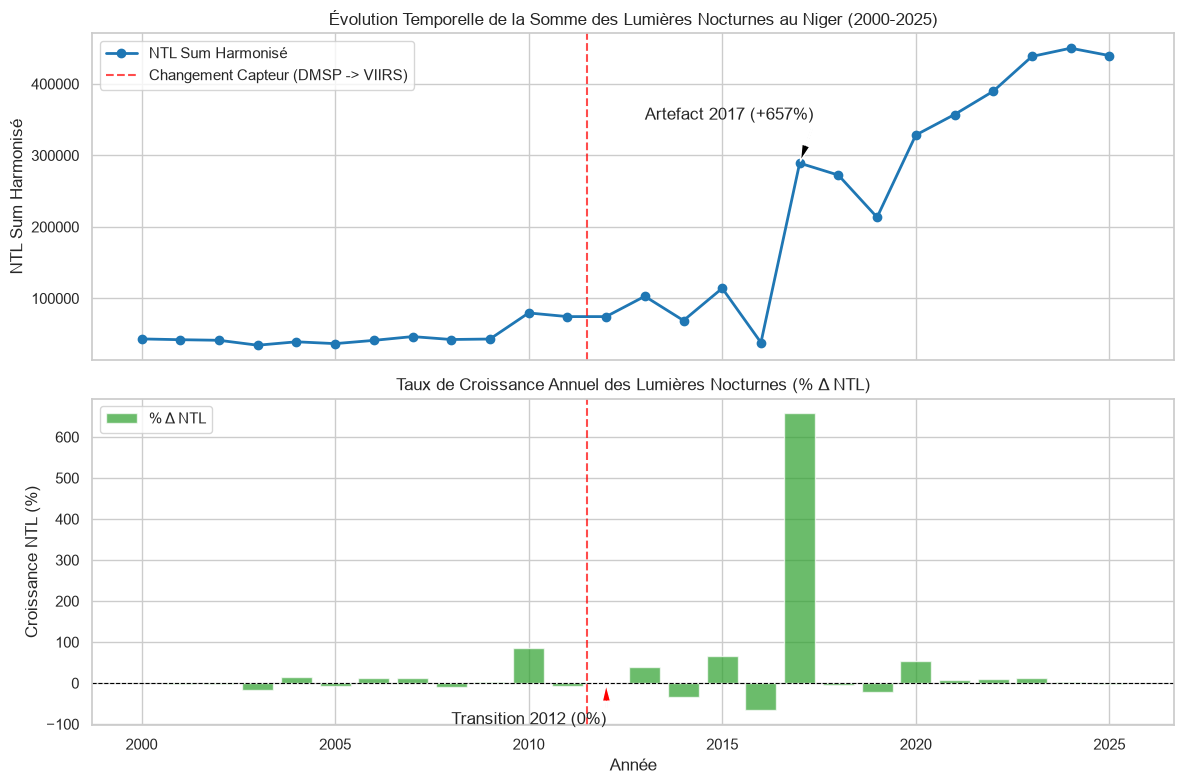

In [12]:
# ==============================================================================
# 5.1 VISUALISATION DES SÉRIES NTL & SAUVEGARDE DE LA FIGURE
# ==============================================================================
# Définition du dossier de sortie pour les figures
project_root = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
figures_dir = project_root / "outputs" / "figures"
figures_dir.mkdir(parents=True, exist_ok=True)

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(12, 8), sharex=True)

# Graphique 1 : Somme des lumières (NTL Sum Adj)
ax1.plot(df_audit['year'], df_audit['ntl_sum_adj'], marker='o', color='#1f77b4', linewidth=2, label='NTL Sum Harmonisé')
ax1.axvline(x=2011.5, color='red', linestyle='--', alpha=0.7, label='Changement Capteur (DMSP -> VIIRS)')
ax1.annotate('Artefact 2017 (+657%)', xy=(2017, 289181), xytext=(2013, 350000),
             arrowprops=dict(facecolor='black', shrink=0.05, width=1, headwidth=6))
ax1.set_ylabel('NTL Sum Harmonisé')
ax1.set_title('Évolution Temporelle de la Somme des Lumières Nocturnes au Niger (2000-2025)')
ax1.legend(loc='upper left')

# Graphique 2 : Taux de Croissance Annuel (% Δ NTL)
df_audit['ntl_growth_clean'] = df_audit['ntl_sum_adj'].pct_change() * 100
ax2.bar(df_audit['year'], df_audit['ntl_growth_clean'], color='#2ca02c', alpha=0.7, label='% Δ NTL')
ax2.axhline(0, color='black', linewidth=0.8, linestyle='--')
ax2.axvline(x=2011.5, color='red', linestyle='--', alpha=0.7)
ax2.annotate('Transition 2012 (0%)', xy=(2012, 0), xytext=(2008, -100),
             arrowprops=dict(facecolor='red', shrink=0.05, width=1, headwidth=6))
ax2.set_ylabel('Croissance NTL (%)')
ax2.set_xlabel('Année')
ax2.set_title('Taux de Croissance Annuel des Lumières Nocturnes (% Δ NTL)')
ax2.legend(loc='upper left')

plt.tight_layout()

# SAUVEGARDE AUTOMATIQUE DE LA FIGURE (PNG HD 300 DPI + PDF vectoriel)
fig_path_png = figures_dir / "01_ntl_anomalies_and_growth.png"
fig_path_pdf = figures_dir / "01_ntl_anomalies_and_growth.pdf"

plt.savefig(fig_path_png, dpi=300, bbox_inches='tight')
plt.savefig(fig_path_pdf, bbox_inches='tight')

print(f"[✓] Figure sauvegardée avec succès dans : {fig_path_png}")
plt.show()

In [13]:
# ==============================================================================
# 5.2 CRÉATION DES DUMMYS DE CONTRÔLE ET EXPORTATION DU DATASET AUDITÉ
# ==============================================================================

# Dummy d'impulsion pour le choc de détection satellitaire de 2017
df_audit['dummy_2017'] = (df_audit['year'] == 2017).astype(int)

# Dummy pour l'année de transition 2012 (croissance nulle issue du raccordement)
df_audit['dummy_trans_2012'] = (df_audit['year'] == 2012).astype(int)

# Dummy pour la période post-2017 (si le changement de niveau de bruit persiste de 2017 à 2025)
df_audit['dummy_post_2017'] = (df_audit['year'] >= 2017).astype(int)

# Mise à jour propre des colonnes de croissance
df_audit['ntl_growth'] = df_audit['ntl_growth_clean']
df_audit['gdp_growth_calc'] = df_audit['gdp_real'].pct_change() * 100

print("--- Résumé des Dummys et Variables de Contrôle générées ---")
cols_audit_summary = ['year', 'gdp_real', 'gdp_pc_local', 'ntl_sum_adj', 'ntl_growth', 'sensor', 'dummy_viirs', 'dummy_2017', 'dummy_trans_2012']
print(df_audit[cols_audit_summary].loc[df_audit['year'].isin([2011, 2012, 2016, 2017, 2018])])

# Exportation vers data/intermediate/ntl_processed/
project_root = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
out_dir = project_root / "data" / "intermediate" / "ntl_processed"
out_dir.mkdir(parents=True, exist_ok=True)

out_file = out_dir / "niger_ntl_audited_2000_2025.csv"
df_audit.to_csv(out_file, index=False)

print(f"\n[✓] Fichier audité enregistré avec succès sous : {out_file}")

--- Résumé des Dummys et Variables de Contrôle générées ---
    year       gdp_real  gdp_pc_local   ntl_sum_adj  ntl_growth    sensor  \
11  2011  4417206977700 257168.968263  74511.381923   -6.435836  DMSP/OLS   
12  2012  4883175693600 273770.193111  74511.381923    0.000000     VIIRS   
16  2016  5970334000000 288620.578618  38173.327183  -66.560810     VIIRS   
17  2017  6300612000000 293934.261970 289181.450618  657.548456     VIIRS   
18  2018  6735013000000 303542.097332 272420.226805   -5.796092     VIIRS   

    dummy_viirs  dummy_2017  dummy_trans_2012  
11            0           0                 0  
12            1           0                 1  
16            1           0                 0  
17            1           1                 0  
18            1           0                 0  

[✓] Fichier audité enregistré avec succès sous : c:\Niger & Big Data\NTL et PIB Niger\niger_ntl_gdp\data\intermediate\ntl_processed\niger_ntl_audited_2000_2025.csv


## Section 6 : Bilan d'Audit & Décision pour la Suite

### 📊 Synthèse de la Qualité des Données
1. **Intégrité Temporelle & Structurelle** : 26 observations annuelles complètes (2000–2025) sans données manquantes ni doublons.
2. **Harmonisation Monétaire** : Création validée de la variable `gdp_pc_local` (FCFA par habitant) pour éviter la confusion d'unité avec le Dollar USD.
3. **Anomalies Satellitaires Documentées** :
   * **2012** : La croissance $NTL = 0\%$ est identifiée comme un artefact de raccordement DMSP/VIIRS $\rightarrow$ Contrôlée par `dummy_trans_2012`.
   * **2017** : Le saut de $+657.5\%$ est un artefact de captage/bruit spatial $\rightarrow$ Contrôlé par `dummy_2017` et `dummy_post_2017`.

---

### 🏁 Décision pour le Notebook 02